# Task 3 Copilot Mode and Programmer Experience
**Damir Makhmutov and Amir Kasimov**

This notebook reproduces our exploratory secondary analysis of 66 published sessions from 33 participants. Manual Copilot invocation is the baseline; both conditions provide AI assistance. Our main question is whether the automatic-minus-manual productivity change differs between experience groups.

Original study: [Guglielmi et al.](https://doi.org/10.1007/s10664-026-10965-6). [Data attribution](../data/README.md). We do not claim new participant data or causal effects of experience.

Run all cells in order with the project dependencies installed. Code lives in `src/`; this notebook explains and displays the calculations.

In [1]:
import csv
import json
import sys
from pathlib import Path
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'configs/config.json').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'configs/config.json').is_file(), 'Run from the repository or notebooks directory'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.process_data import read_data, paired_changes
from src.task3_analysis import build_analysis, save_analysis, metric_rows
from src.runtime_benchmark import summarize_runtime
from src.visualize import draw_figures
print('Python:', sys.version.split()[0])
print('Human bootstrap: 10,000 paired draws within groups; seed 42.')

Python: 3.12.14
Human bootstrap: 10,000 paired draws within groups; seed 42.


## 1 Data ingestion and validation
The original CSV bytes are retained. Loading checks SHA-256 hashes, numeric bounds, published productivity, task assignments, and exactly two valid sessions per participant. Zero-completion sessions are kept. Human task sessions have no technical warm-up phase; none are discarded as cold starts.

Productivity is completed task fraction per hour: `(completion_pct / 100) / (time_minutes / 60)`. Session time is not necessarily time to a fully completed solution.

In [2]:
config = json.loads((ROOT / 'configs/config.json').read_text())
records = read_data(ROOT, config)
pairs = paired_changes(records)
assert len(records) == 66 and len(pairs) == 33
print('Validated sessions:', len(records))
print('Complete participant pairs:', len(pairs))
print('Zero-completion sessions retained:', sum(r['completion_pct'] == 0 for r in records))
print('Experience counts:', {g: sum(r['experience_group'] == g for r in pairs) for g in ('novice', 'expert')})
print('Example validated session:', records[0])

Validated sessions: 66
Complete participant pairs: 33
Zero-completion sessions retained: 3
Experience counts: {'novice': 17, 'expert': 16}
Example validated session: {'participant_id': 'unimol002', 'experience_group': 'expert', 'sequence': 'A', 'mode': 'automatic', 'task': 'A', 'completion_pct': 12.5, 'time_minutes': 90.0, 'productivity_per_hour': 0.08333333333333333}


## 2 Statistical aggregation
Recalculate summaries and participant-pair bootstrap estimates from source data. Sample SD describes participant dispersion; the 95% bootstrap CI describes estimation uncertainty. Percentiles use linear interpolation. We preserve pairing and do not treat 66 sessions as 66 independent people.

In [3]:
results = build_analysis(ROOT)
save_analysis(ROOT, results)
lines = ['| Group | Mode | Metric | Unit | n | Mean | SD | Median | p25 | p75 | p95 |',
         '| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |']
for r in metric_rows(results):
    values = [r['experience_group'], r['mode'], r['metric'], r['unit'], str(r['n'])]
    values += [f"{r[k]:.3f}" for k in ('mean', 'sd', 'median', 'p25', 'p75', 'p95')]
    lines.append('| ' + ' | '.join(values) + ' |')
display(Markdown('\n'.join(lines)))
print('Saved source-derived sessions, paired changes, summaries, and results to data/processed/.')

| Group | Mode | Metric | Unit | n | Mean | SD | Median | p25 | p75 | p95 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| novice | manual | productivity_per_hour | completed task fraction/hour | 17 | 0.182 | 0.153 | 0.150 | 0.125 | 0.200 | 0.480 |
| novice | manual | completion_pct | percent | 17 | 18.824 | 16.773 | 15.000 | 12.500 | 20.000 | 52.000 |
| novice | manual | time_minutes | minutes | 17 | 60.588 | 4.963 | 60.000 | 60.000 | 60.000 | 66.000 |
| novice | automatic | productivity_per_hour | completed task fraction/hour | 17 | 0.472 | 0.262 | 0.462 | 0.333 | 0.500 | 0.938 |
| novice | automatic | completion_pct | percent | 17 | 51.029 | 25.831 | 50.000 | 37.500 | 62.500 | 100.000 |
| novice | automatic | time_minutes | minutes | 17 | 67.235 | 10.426 | 60.000 | 60.000 | 70.000 | 86.000 |
| expert | manual | productivity_per_hour | completed task fraction/hour | 16 | 0.789 | 0.213 | 0.750 | 0.613 | 0.881 | 1.137 |
| expert | manual | completion_pct | percent | 16 | 78.750 | 15.055 | 77.500 | 71.875 | 88.125 | 100.000 |
| expert | manual | time_minutes | minutes | 16 | 61.750 | 11.000 | 60.000 | 58.750 | 62.500 | 81.250 |
| expert | automatic | productivity_per_hour | completed task fraction/hour | 16 | 0.513 | 0.338 | 0.410 | 0.269 | 0.762 | 1.008 |
| expert | automatic | completion_pct | percent | 16 | 55.781 | 30.079 | 52.500 | 34.375 | 82.500 | 92.500 |
| expert | automatic | time_minutes | minutes | 16 | 69.438 | 12.296 | 66.500 | 60.000 | 80.000 | 90.000 |

Saved source-derived sessions, paired changes, summaries, and results to data/processed/.


## 3 Research questions and uncertainty
RQ1 and RQ2 estimate the mean automatic-minus-manual productivity change within each group. RQ3 directly compares the two mean changes: experts minus novices. A negative RQ3 estimate means a smaller automatic-relative-to-manual change for experts.

Intervals are exploratory, not preregistered confirmatory tests. The primary contrast is computed directly; comparing two within-group significance decisions would not answer RQ3.

In [4]:
for question, group in [('RQ1', 'novice'), ('RQ2', 'expert')]:
    r = results['by_group'][group]['paired_changes']['productivity_per_hour_change']
    print(f"{question} ({group}): {r['mean']:+.4f}; 95% CI [{r['ci95'][0]:+.4f}, {r['ci95'][1]:+.4f}]")
r = results['primary_contrast']
print(f"RQ3 (expert minus novice): {r['estimate']:+.4f}; 95% CI [{r['ci95'][0]:+.4f}, {r['ci95'][1]:+.4f}]")
print('Unit: completed task fraction/hour.')

RQ1 (novice): +0.2901; 95% CI [+0.1338, +0.4560]
RQ2 (expert): -0.2759; 95% CI [-0.4954, -0.0489]
RQ3 (expert minus novice): -0.5660; 95% CI [-0.8387, -0.2839]
Unit: completed task fraction/hour.


## 4 Completion guardrail and sensitivity
A mean completion drop greater than 5 percentage points triggers our reporting flag. This threshold is chosen for the project, not a validated quality or security standard.

We check whether excluding one participant reverses the main contrast. We also equally weight automatic-task A and B within each experience group. This does not adjust session order: the CSV labels A–D do not explicitly map to the paper's numbered sequences. No period is guessed from row order.

In [5]:
for group in ('novice', 'expert'):
    r = results['by_group'][group]
    completion = r['paired_changes']['completion_pct_change']['mean']
    time_change = r['paired_changes']['time_minutes_change']['mean']
    print(f"{group}: completion {completion:+.2f} pp; time {time_change:+.2f} min; guardrail met: {r['completion_guardrail_met']}")
loo = results['leave_one_out']
print(f"Leave-one-out range: [{loo['min']:+.4f}, {loo['max']:+.4f}]; sign changed: {loo['sign_changed']}")
print('This sensitivity range is not a confidence interval.')
sensitivity = results['task_allocation_sensitivity']
print('Equal-task-weight contrast:', round(sensitivity['primary_contrast'], 4))
print(sensitivity['limitation'])

novice: completion +32.21 pp; time +6.65 min; guardrail met: True
expert: completion -22.97 pp; time +7.69 min; guardrail met: False
Leave-one-out range: [-0.6233, -0.5200]; sign changed: False
This sensitivity range is not a confidence interval.
Equal-task-weight contrast: -0.5773
Task-allocation sensitivity only; session order and carryover are not adjusted.


## 5 Separate technical benchmark and warm-up filtering
The JSONL file contains real timings of our CSV parser and pair validator, not participant outcomes. The collector preloads source text, then times only parsing and validation. Hash checks, file reads, log writing, and aggregation are outside the timer.

For each input size, discard the 20 records labelled `warmup` and retain the 100 labelled `benchmark`. Count errors in the denominator. Successful timings supply latency summaries; IQR flags retain outliers. A fixed seed makes bootstrap summaries reproducible for fixed logs, but collecting new timings changes them.

Use `python -m src.runtime_benchmark` to collect a new run; the complete rebuild command also does this. Here we analyze the retained log, so this notebook can inspect the submitted run without replacing it.

In [6]:
logs = [json.loads(line) for line in (ROOT / 'data/raw/test_run.jsonl').read_text().splitlines()]
runtime_config = json.loads((ROOT / 'configs/runtime.json').read_text())
runtime = summarize_runtime(logs, runtime_config)
print('Warm-up attempts excluded:', sum(r['phase'] == 'warmup' for r in logs))
print('Evaluation attempts retained:', sum(r['phase'] == 'benchmark' for r in logs))
for r in runtime:
    print(f"{r['input_rows']} rows: {r['attempts']} attempts, {r['errors']} errors ({r['error_rate']:.1%}); "
          f"mean {r['mean_ms']:.4f} ms, 95% CI [{r['ci95_low_ms']:.4f}, {r['ci95_high_ms']:.4f}], "
          f"median {r['median_ms']:.4f}, p95 {r['p95_ms']:.4f}, {r['iqr_flags']} IQR flags kept")
metadata = json.loads((ROOT / 'data/raw/runtime_metadata.json').read_text())
print('Measurement environment:', json.dumps(metadata, indent=2))

Warm-up attempts excluded: 40
Evaluation attempts retained: 200
8 rows: 100 attempts, 0 errors (0.0%); mean 0.0474 ms, 95% CI [0.0471, 0.0478], median 0.0470, p95 0.0486, 5 IQR flags kept
66 rows: 100 attempts, 0 errors (0.0%); mean 0.3266 ms, 95% CI [0.3170, 0.3381], median 0.3107, p95 0.4090, 12 IQR flags kept
Measurement environment: {
  "collected_at_utc": "2026-11-05T18:13:59.699367+00:00",
  "python": "3.12.14",
  "os": "Windows-11-10.0.26200-SP0",
  "processor": "AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD",
  "logical_cpus": 12,
  "config": {
    "warmup_runs": 20,
    "evaluation_runs": 100,
    "bootstrap_repetitions": 2000,
    "random_seed": 42
  },
  "clock": "time.perf_counter_ns",
  "measured_operation": "Parse preloaded CSV strings and validate participant pairs",
  "excluded_from_timer": "File reading, source hash checks, log writes, and summary calculation",
  "interpretation": "Local repeated timings of one fixed input; not human productivity evidence",
  "ram_

## 6 Visualization and export
Export every figure as a vector PDF and a 300-DPI PNG to `reports/figures/`. Physical outcomes have units; categorical axes name the groups or modes. Colors are from a colorblind-safe palette and are paired with different markers. We use linear scales because paired changes include zero and negative values.

Figure 1 shows paired means and 95% CIs. Figure 2 shows all participant pairs, median/IQR boxes, and mean/95% CI markers. Figure 3 separates completion from time. Figure 4 is the separate local runtime benchmark.

**fig1 paired changes**

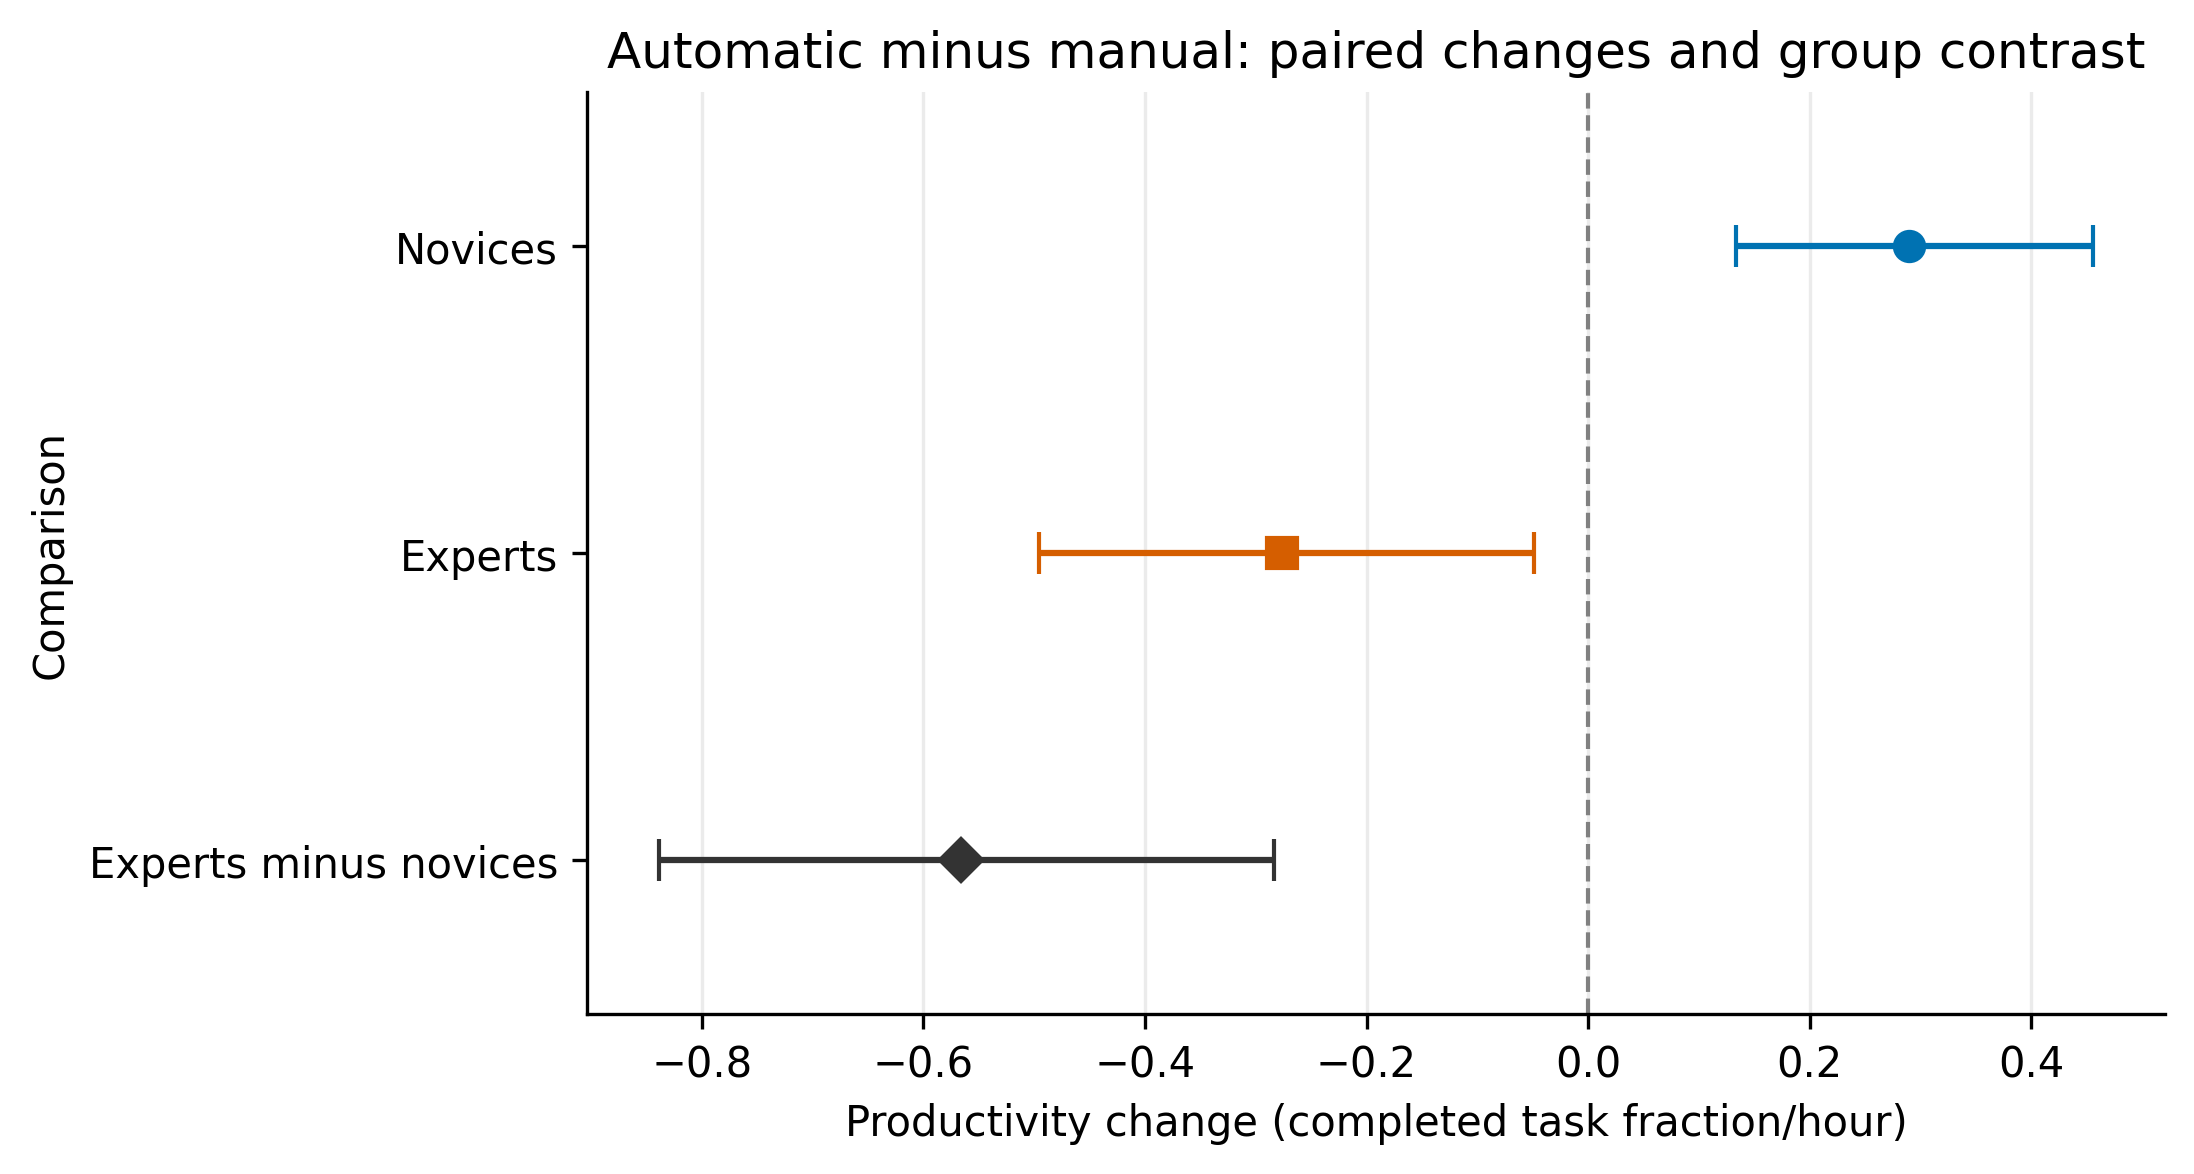

**fig2 productivity distribution**

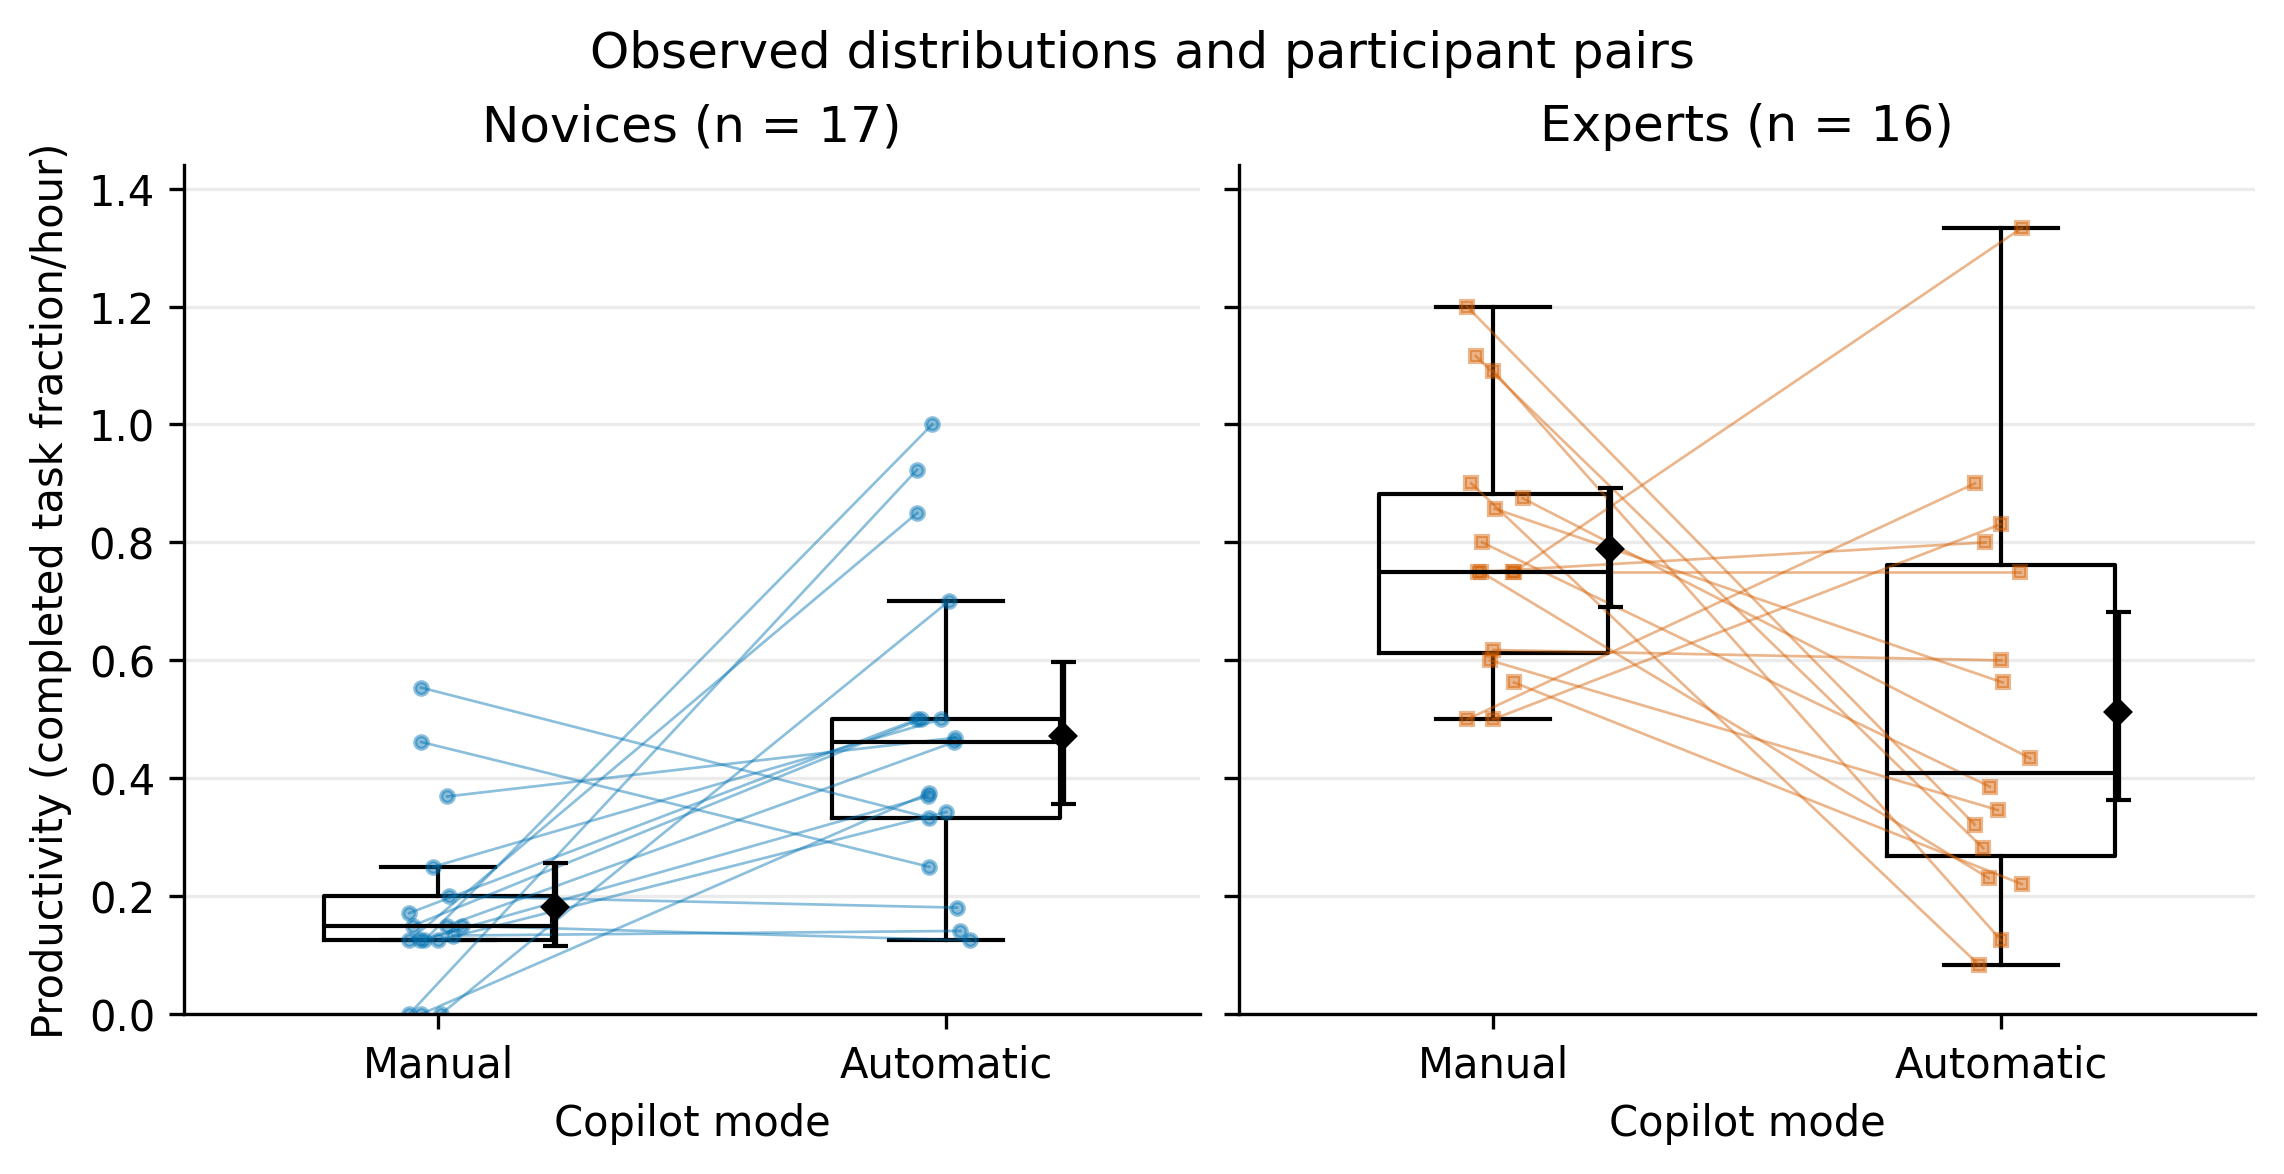

**fig3 completion time**

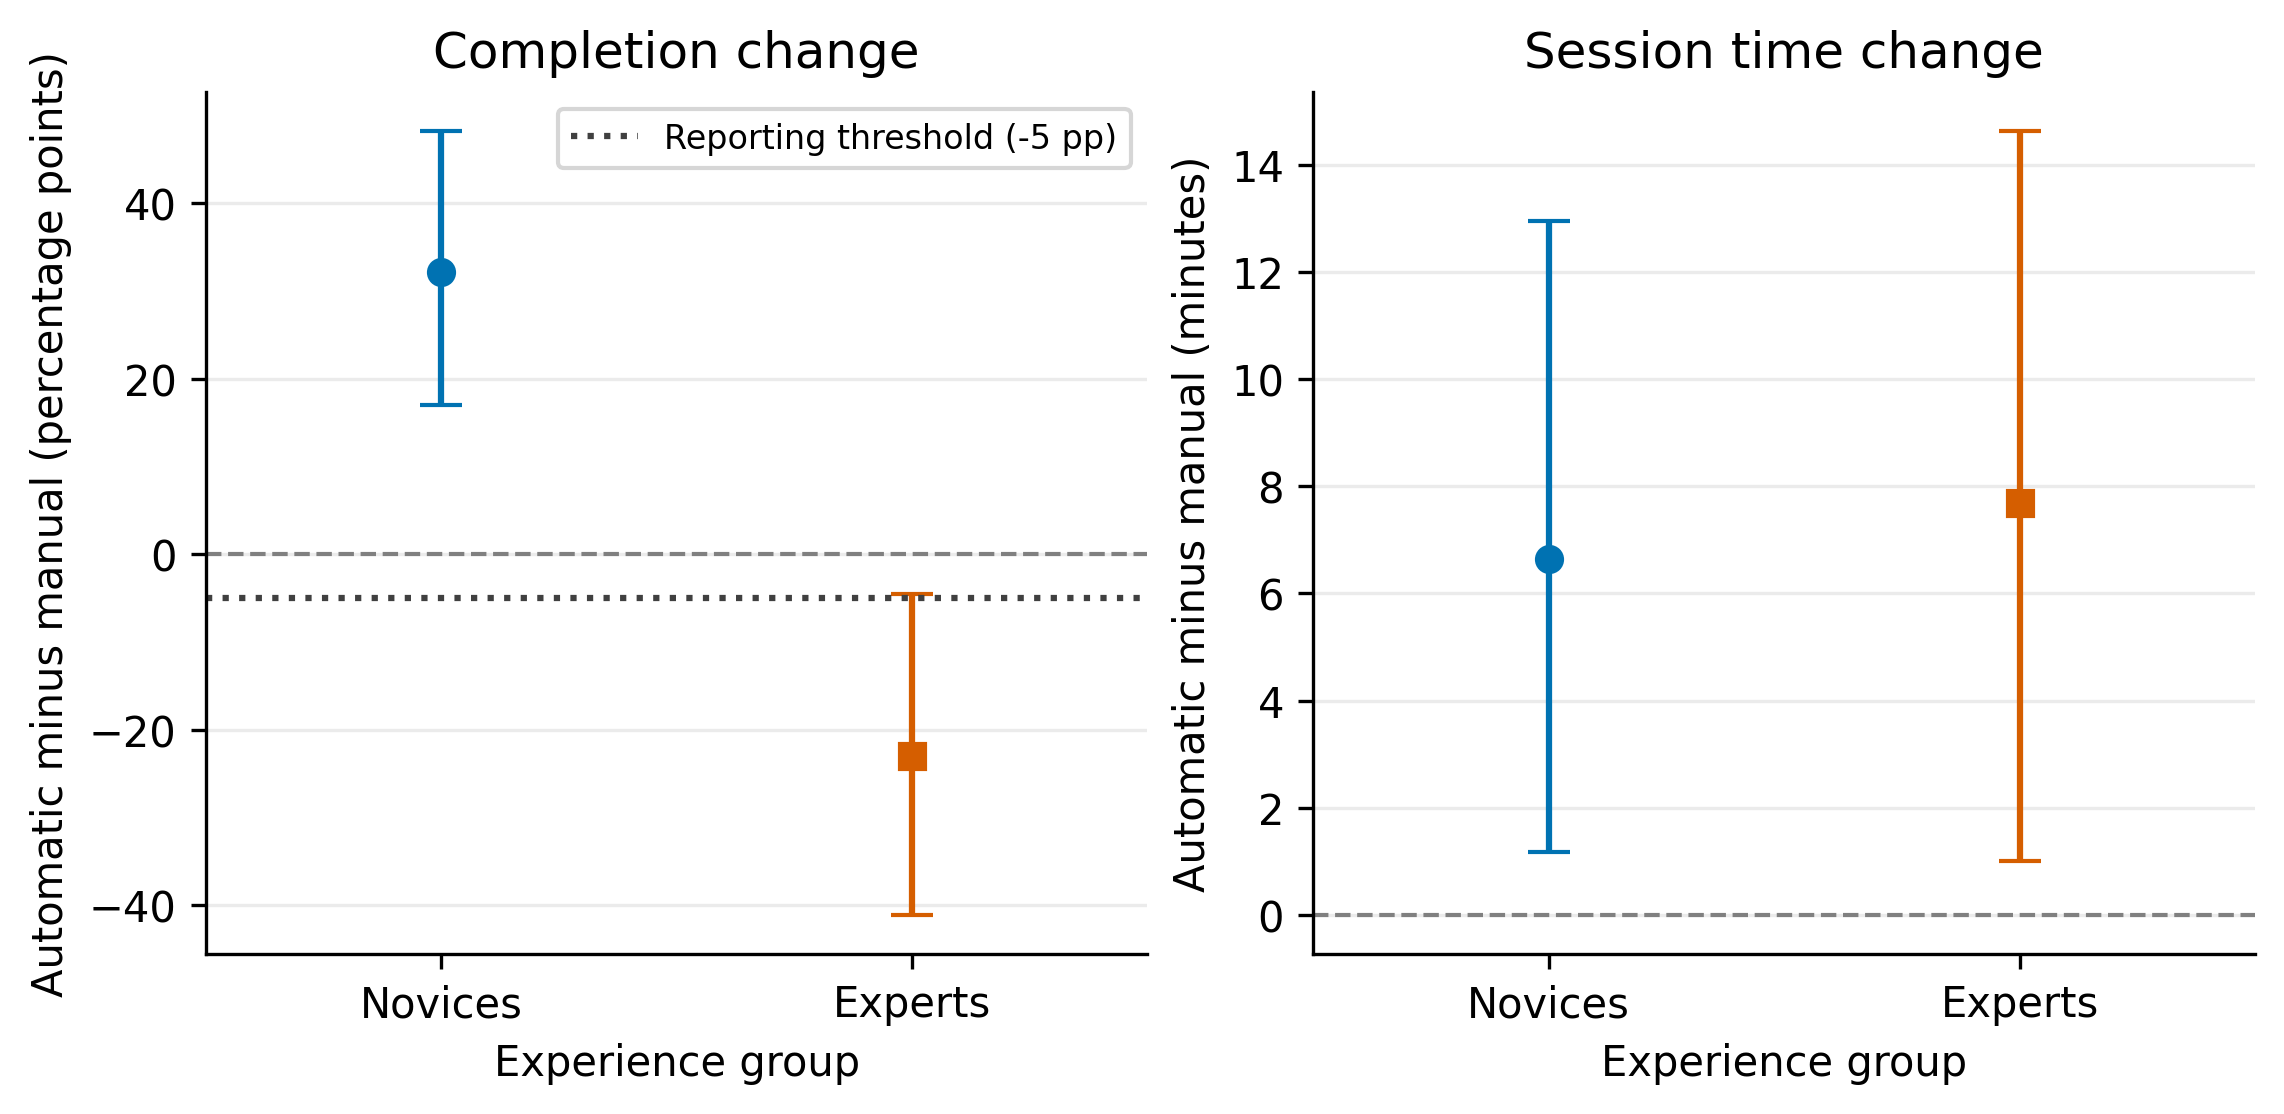

**fig4 runtime**

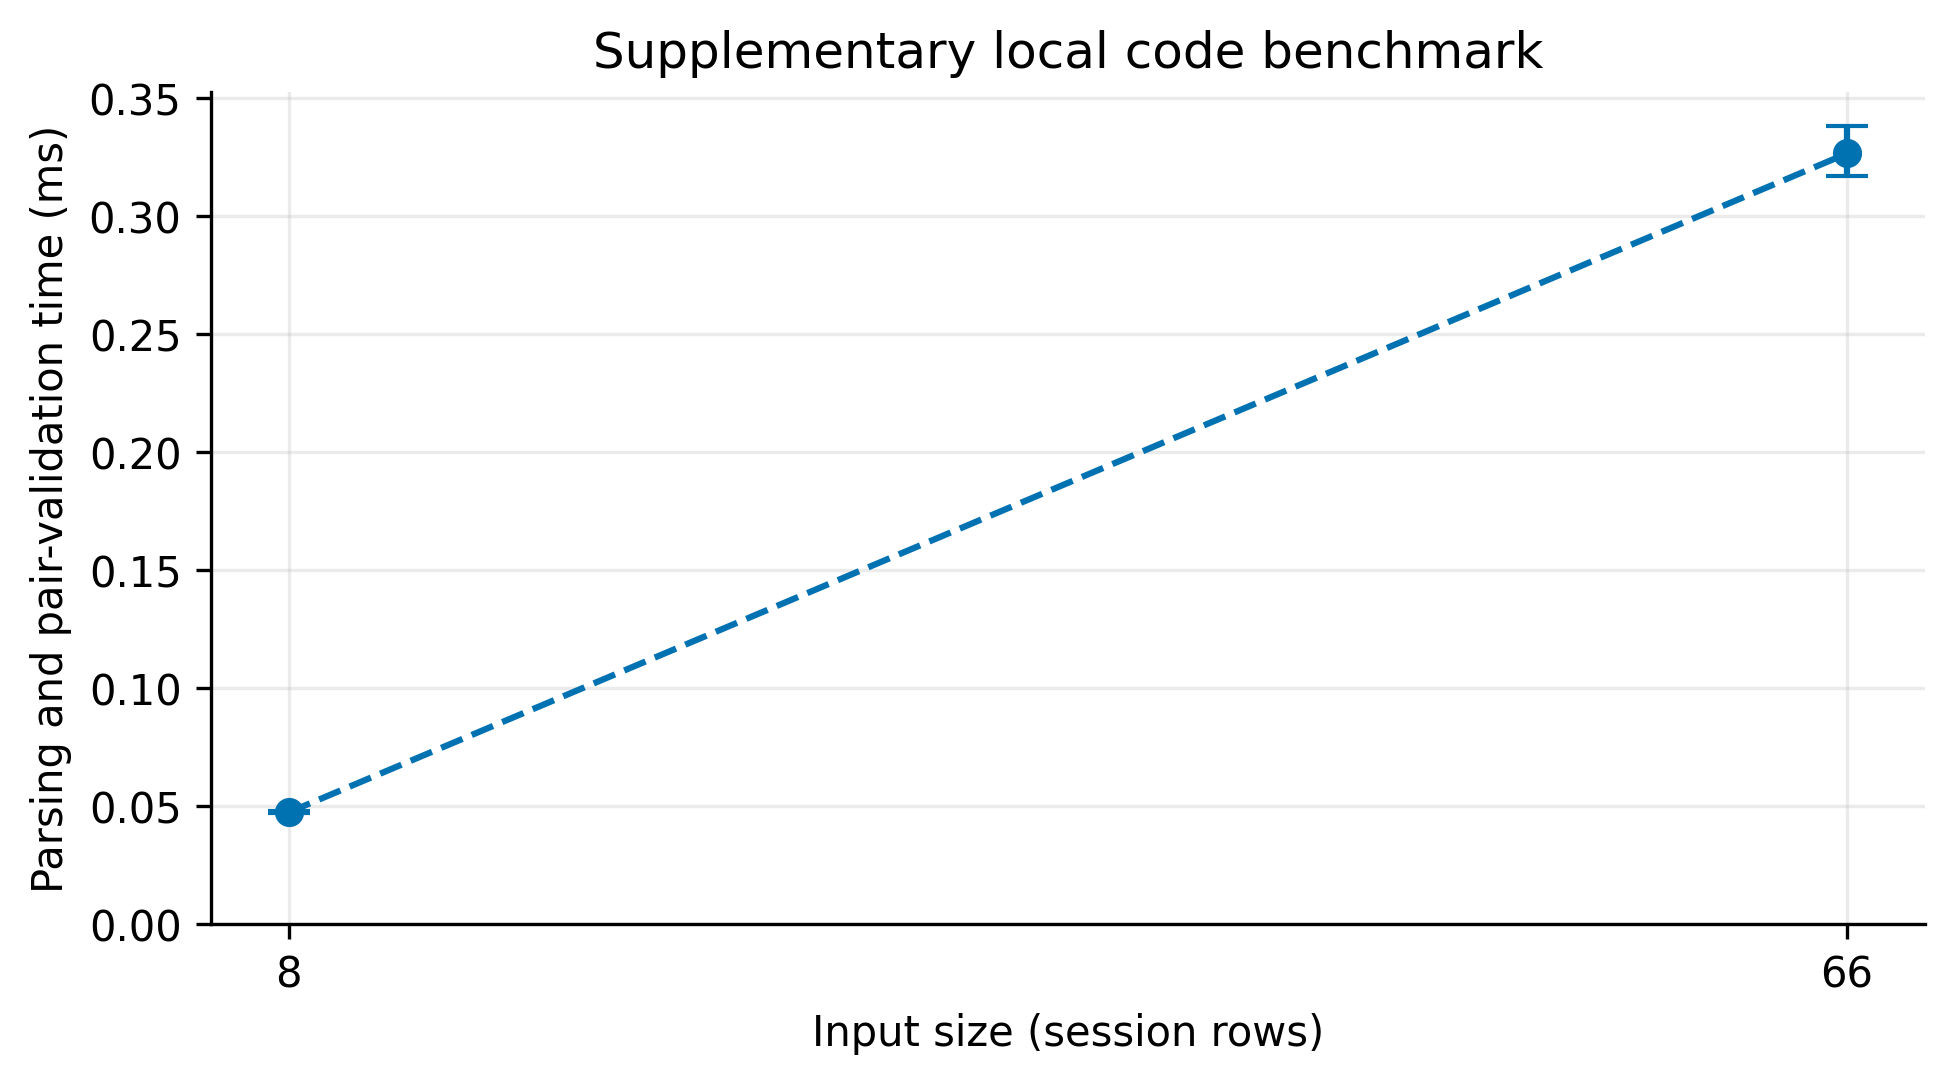

Exported 4 vector PDF / 300-DPI PNG pairs.


In [7]:
figures = draw_figures(ROOT)
for path in figures:
    display(Markdown('**' + path.stem.replace('_', ' ') + '**'))
    display(Image(filename=str(path), width=780))
print('Exported', len(figures), 'vector PDF / 300-DPI PNG pairs.')

## 7 Interpretation and limits
Within this published sample, automatic suggestions are associated with higher novice productivity and lower expert productivity. Completion changes follow opposite directions, while time increases in both groups. The novice productivity result must not be called faster task completion.

The negative direct group contrast persists under single-participant exclusion and equal task weighting. This does not remove task, period, carryover, selection, or experience confounding. The convenience sample is small, experience was not randomized, both modes use Copilot, and completion is not a security score. Our data and published findings were inspected before the analysis plan.

Technical timings describe one local sequential run on fixed inputs. Background load and correlated repeats limit their intervals. They do not add human evidence. See the [domain model](../docs/domain_model.md), [full report](../reports/task3_report.md), and [requirements checklist](../docs/task3_checklist.md).

In [8]:
from src.check_submission import check
print('All analysis cells completed. Human sample:', results['participants'], 'participants.')
print('Primary unadjusted contrast:', round(results['primary_contrast']['estimate'], 4))
print('Figures and report are saved; the runner validates the notebook after execution.')

All analysis cells completed. Human sample: 33 participants.
Primary unadjusted contrast: -0.566
Figures and report are saved; the runner validates the notebook after execution.
